# Estimativa de Tempo BIG O (Matriz F.O.C.A.)
Este notebook contém os scripts para a medição empírica das 4 macro-primitivas solicitadas:
- `execution_time_Atrib.py` (Atribuições - $\tau_a$)
- `execution_time_Comp.py` (Comparações - $\tau_c$)
- `execution_time_Oper.py` (Operações Matemáticas - $\tau_o$)
- `execution_time_Func.py` (Funções Opacas - $F$)

O **Tamanho da Amostra Interna (n)** foi configurado para 100 ciclos, e o **Número de Repetições Globais (r)** para 100.000 (R = 100000), gerando uma massa de dados adequada para visualização das anomalias de SO e CPU.

In [ ]:
import os

print("Diretório atual:")
print(os.getcwd())

print("\nArquivos encontrados:")
for arquivo in os.listdir('..'):
    print(arquivo)

Diretório atual:
/home/s-cesar/codes/softwareEngineerDocs/docs/trabalho02

Arquivos encontrados:
run_benchmarks.py
times_Atrib.json
samuca_files
histograma_bruto_macro
estimativa_tempo_BIG_O.ipynb
trabalho01
make_nb.py
times_Func.json
resumo_micro_primitivas.csv
trabalho02
images
resumo_calibracao.csv
gerar_paineis_calibracao.py
plot_histograma_bruto.py
get_stats.py
gerar_macro.py
times_Comp.json
.~lock.RTA - Validação de Setup Computacional V3.docx#
times_Oper.json


Gerando gráficos de dispersão 100% brutos...


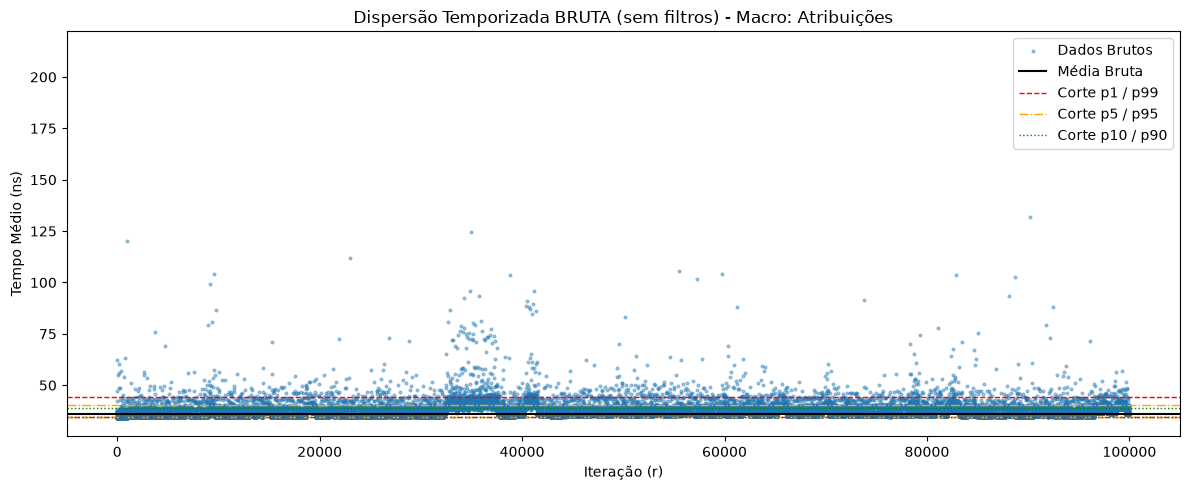

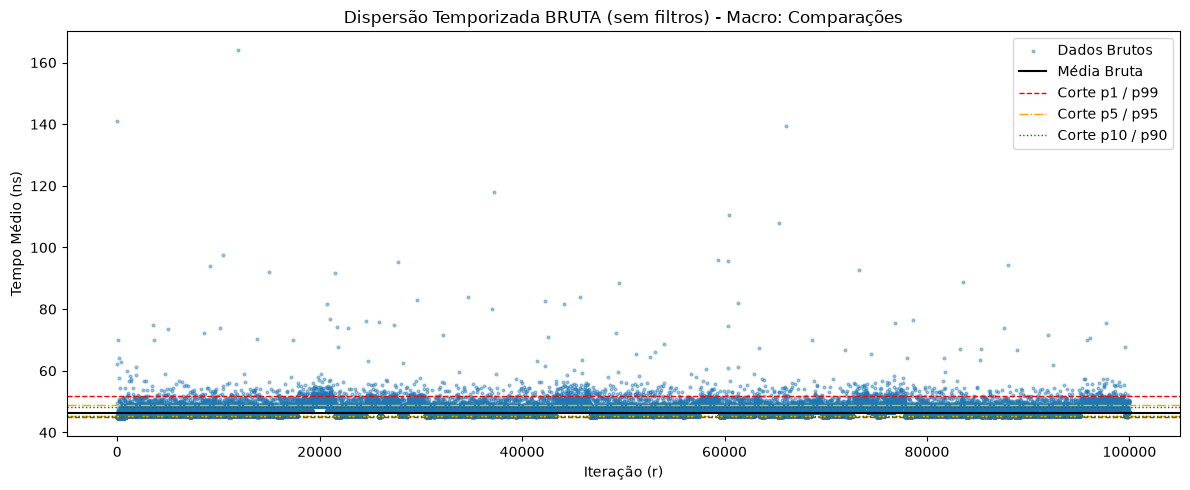

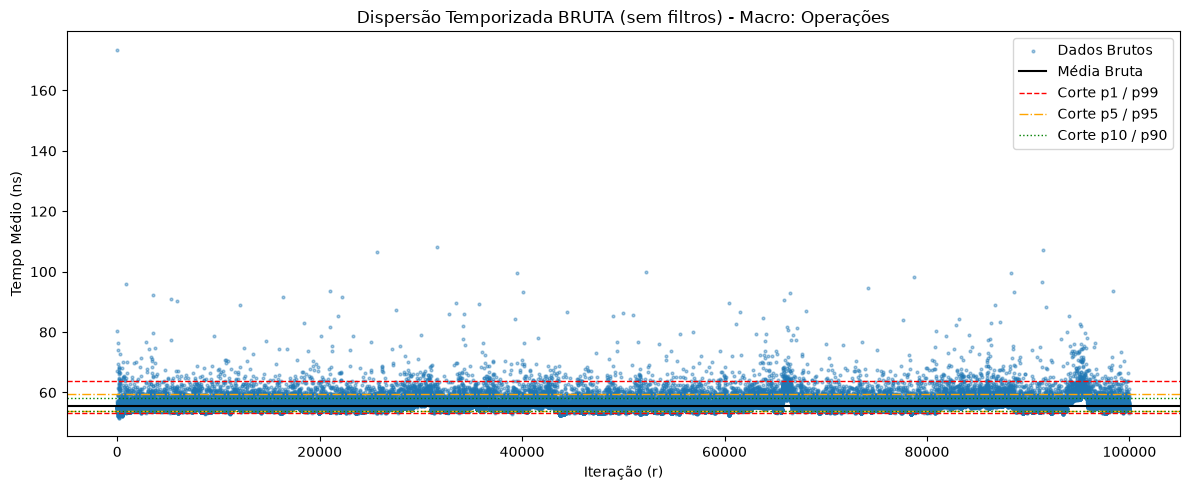

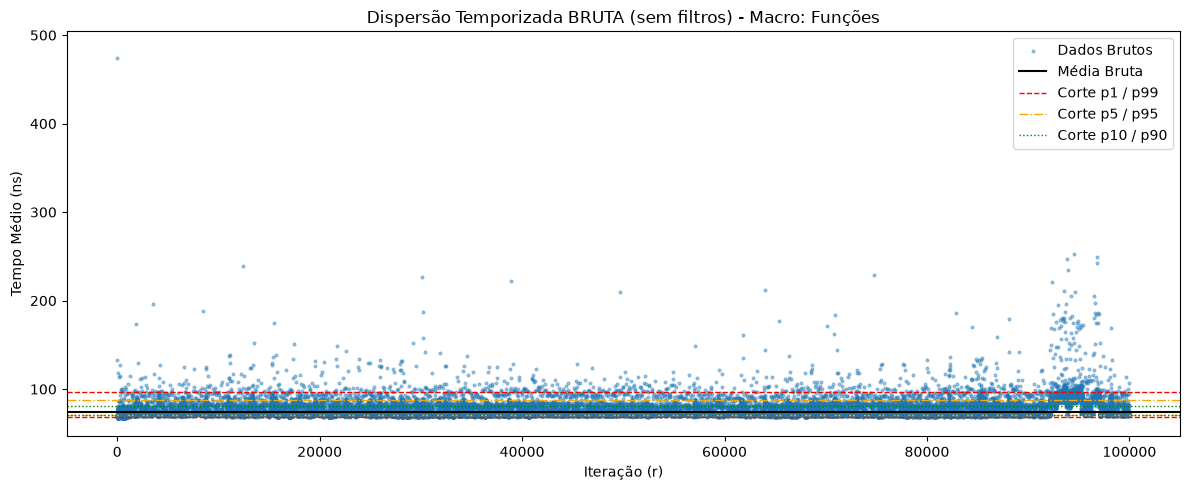

In [4]:
import json
import os
import numpy as np
import matplotlib as plt
import matplotlib.pyplot as plt

CONFIG = {
    "arquivos": {
        "Atribuições": "../times_Atrib.json",
        "Comparações": "../times_Comp.json",
        "Operações": "../times_Oper.json",
        "Funções": "../times_Func.json"
    },
    "output_dir": "dispersao_bruta_macro",
    "n_amostra_interna": 100
}

os.makedirs(CONFIG["output_dir"], exist_ok=True)

print("Gerando gráficos de dispersão 100% brutos...")

for nome_macro, arquivo in CONFIG["arquivos"].items():
    if not os.path.exists(arquivo):
        continue
    
    with open(arquivo, "r") as f:
        dados = json.load(f)
        
    listas_micro = []
    for op, tempos in dados.items():
        # Convertendo tempo para nanosegundos por operação
        arr = (np.array(tempos, dtype=float) * 1e9) / CONFIG["n_amostra_interna"]
        listas_micro.append(arr)
        
    # Agregando para a Macro-Primitiva (Tempo Médio por iteração r)
    arr_macro = np.mean(listas_micro, axis=0)
    iteracoes = np.arange(1, len(arr_macro) + 1)
    
    plt.figure(figsize=(12, 5))
    plt.scatter(iteracoes, arr_macro, alpha=0.4, s=4, color="tab:blue", label="Dados Brutos")
    plt.axhline(np.mean(arr_macro), color="black", linestyle="-", linewidth=1.5, label="Média Bruta")
    
    # Adicionando linhas de referência de percentis para ajudar na decisão visual
    p1, p5, p10 = np.percentile(arr_macro, [1, 5, 10])
    p90, p95, p99 = np.percentile(arr_macro, [90, 95, 99])
    
    plt.axhline(p99, color="red", linestyle="--", linewidth=1, label="Corte p1 / p99")
    plt.axhline(p1, color="red", linestyle="--", linewidth=1)
    
    plt.axhline(p95, color="orange", linestyle="-.", linewidth=1, label="Corte p5 / p95")
    plt.axhline(p5, color="orange", linestyle="-.", linewidth=1)

    plt.axhline(p90, color="green", linestyle=":", linewidth=1, label="Corte p10 / p90")
    plt.axhline(p10, color="green", linestyle=":", linewidth=1)
    
    plt.title(f"Dispersão Temporizada BRUTA (sem filtros) - Macro: {nome_macro}")
    plt.xlabel("Iteração (r)")
    plt.ylabel("Tempo Médio (ns)")
    
    # Usando escala logarítmica no eixo Y se houver picos muito gigantescos, 
    # mas para ns lineares ajuda a ver os GC pauses reais. Vamos manter linear.
    plt.legend(loc="upper right")
    plt.tight_layout()
    
    # out_file = os.path.join(CONFIG["output_dir"], f"dispersao_bruta_{nome_macro}.png")
    # plt.savefig(out_file, dpi=150)
    # plt.close()
    plt.show()
    
    # print(f" -> Salvo: {out_file}")

In [ ]:
import json
import os
import numpy as np

# ==========================================
# CONFIGURAÇÃO DOS PERCENTIS DE CORTE
# ==========================================
PERCENTIL_INFERIOR = 5
PERCENTIL_SUPERIOR = 95

# Amostra interna (para dividir o tempo do laço)
N_AMOSTRA = 100

arquivos = [
    "../times_Atrib.json",
    "../times_Comp.json",
    "../times_Oper.json",
    "../times_Func.json"
]

print(
    f"Análise de Micro-primitivas "
    f"(Cortes: p{PERCENTIL_INFERIOR} a p{PERCENTIL_SUPERIOR})"
)

print(
    "Os valores estão em Nanosegundos (ns) "
    "por operação para facilitar a leitura.\n"
)

header = (
    f"{'Micro-Primitiva':<25} | "
    f"{'Média Bruta':<12} | "
    f"{'Desvio Bruto':<12} | "
    f"{'CV Bruto':<8} || "
    f"{'Média Fil.':<12} | "
    f"{'Desvio Fil.':<12} | "
    f"{'CV Filtrado':<10}"
)

print(header)
print("-" * len(header))

for arquivo in arquivos:

    if not os.path.exists(arquivo):
        print(f"Arquivo não encontrado: {arquivo}")
        continue

    with open(arquivo, "r") as f:
        dados = json.load(f)

    for op, tempos in dados.items():

        # JSON salvo em segundos.
        # Conversão para nanosegundos e divisão
        # pelo número de amostras internas.
        arr = (
            np.array(tempos, dtype=float) * 1e9
        ) / N_AMOSTRA

        # ==========================================
        # ESTATÍSTICAS BRUTAS
        # ==========================================
        mu_bruta = np.mean(arr)
        std_bruta = np.std(arr, ddof=1)

        cv_bruta = (
            std_bruta / mu_bruta
            if mu_bruta > 0
            else 0
        )

        # ==========================================
        # FILTRO POR PERCENTIS
        # ==========================================
        p_low = np.percentile(
            arr,
            PERCENTIL_INFERIOR
        )

        p_high = np.percentile(
            arr,
            PERCENTIL_SUPERIOR
        )

        arr_fil = arr[
            (arr >= p_low) &
            (arr <= p_high)
        ]

        # ==========================================
        # ESTATÍSTICAS PÓS-FILTRO
        # ==========================================
        mu_fil = np.mean(arr_fil)
        std_fil = np.std(arr_fil, ddof=1)

        cv_fil = (
            std_fil / mu_fil
            if mu_fil > 0
            else 0
        )

        print(
            f"{op:<25} | "
            f"{mu_bruta:<12.2f} | "
            f"{std_bruta:<12.2f} | "
            f"{cv_bruta:<8.4f} || "
            f"{mu_fil:<12.2f} | "
            f"{std_fil:<12.2f} | "
            f"{cv_fil:<10.4f}"
        )

print("-" * len(header))
print(
    "DICA: Altere as variáveis PERCENTIL_INFERIOR "
    "e PERCENTIL_SUPERIOR no código para testar novos cortes."
)

Análise de Micro-primitivas (Cortes: p5 a p95)
Os valores estão em Nanosegundos (ns) por operação para facilitar a leitura.

Micro-Primitiva           | Média Bruta  | Desvio Bruto | CV Bruto || Média Fil.   | Desvio Fil.  | CV Filtrado
---------------------------------------------------------------------------------------------------------------
var_int_cte_int           | 31.34        | 3.57         | 0.1138   || 30.97        | 0.15         | 0.0050    
var_float_cte_float       | 33.24        | 4.92         | 0.1480   || 32.47        | 0.42         | 0.0131    
var_bool_cte_bool         | 33.17        | 5.48         | 0.1652   || 32.53        | 2.10         | 0.0645    
var_int_var_int           | 40.74        | 9.13         | 0.2242   || 39.38        | 3.82         | 0.0969    
var_float_var_float       | 42.06        | 5.10         | 0.1213   || 41.42        | 0.30         | 0.0073    
cte_int_eq_cte_int        | 36.45        | 4.34         | 0.1191   || 35.87        | 0.93       

### Análise e Filtragem de Outliers
Altere as variáveis `lower_q` (Quartil Inferior) e `upper_q` (Quartil Superior) abaixo para testar diferentes filtragens de outliers (ex: 25 e 75 para considerar só o IQR - Intervalo Interquartil, ou 1 e 99 para excluir os top e bottom 1%). O ideal é garantir um CV Filtrado < 0.15.

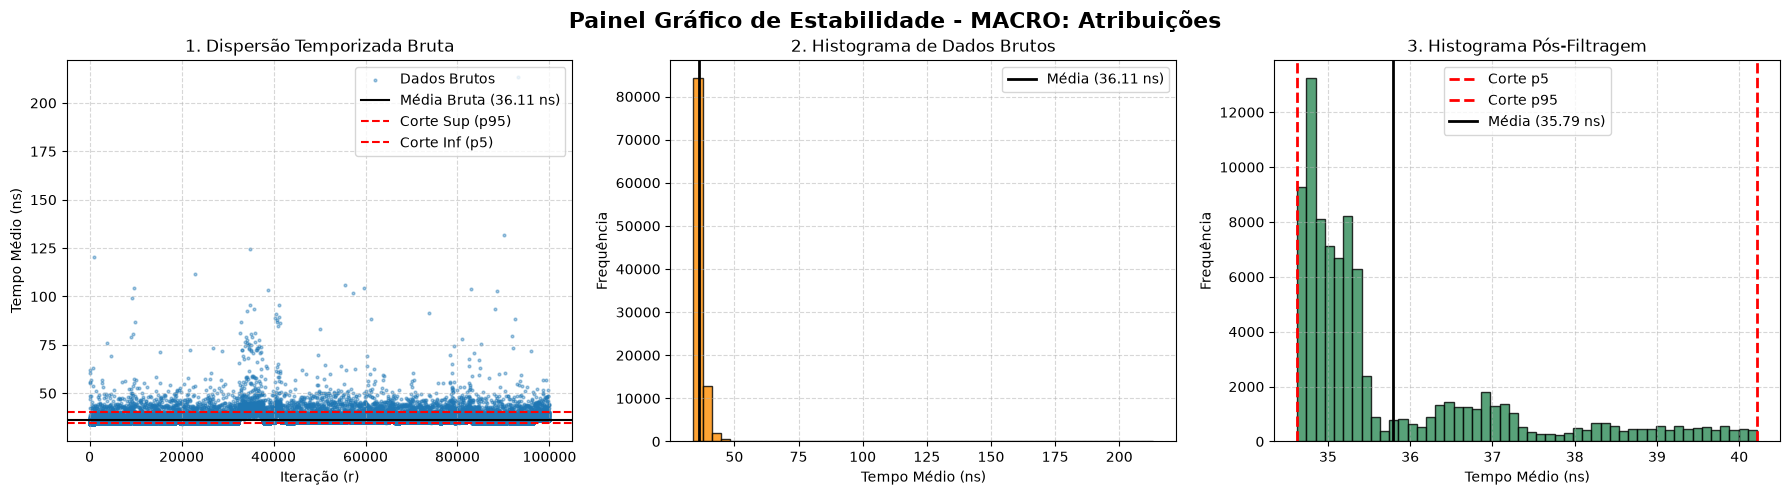

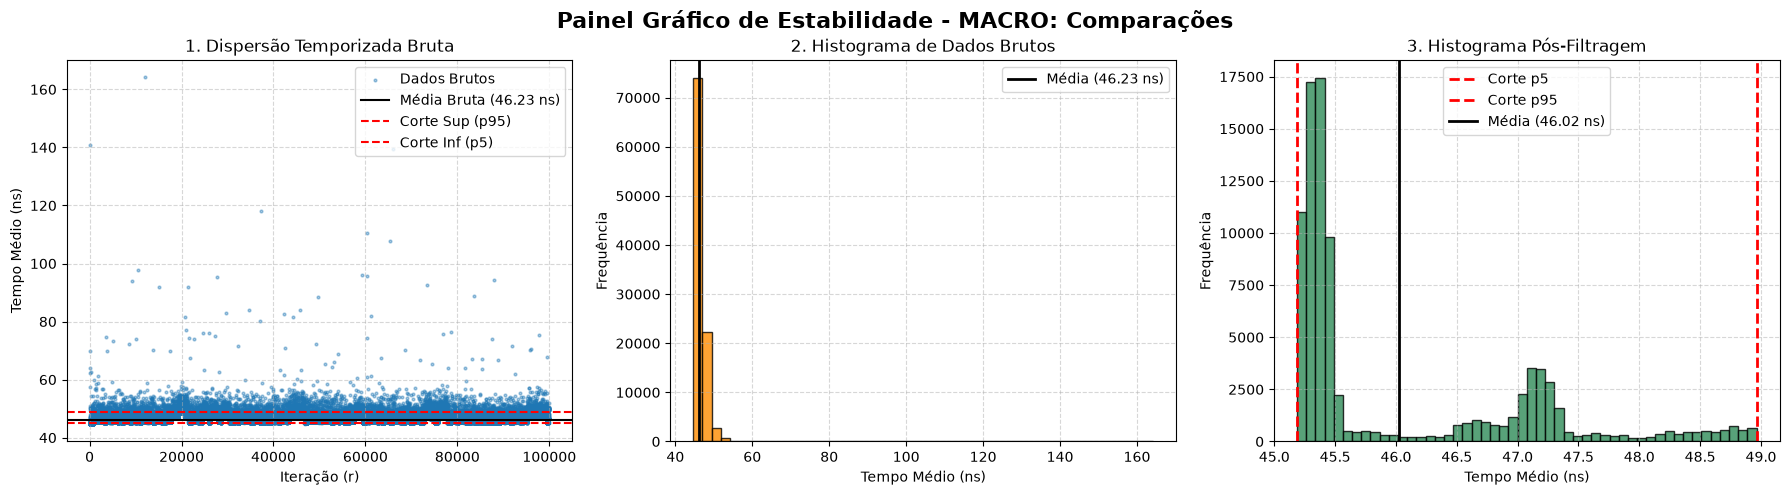

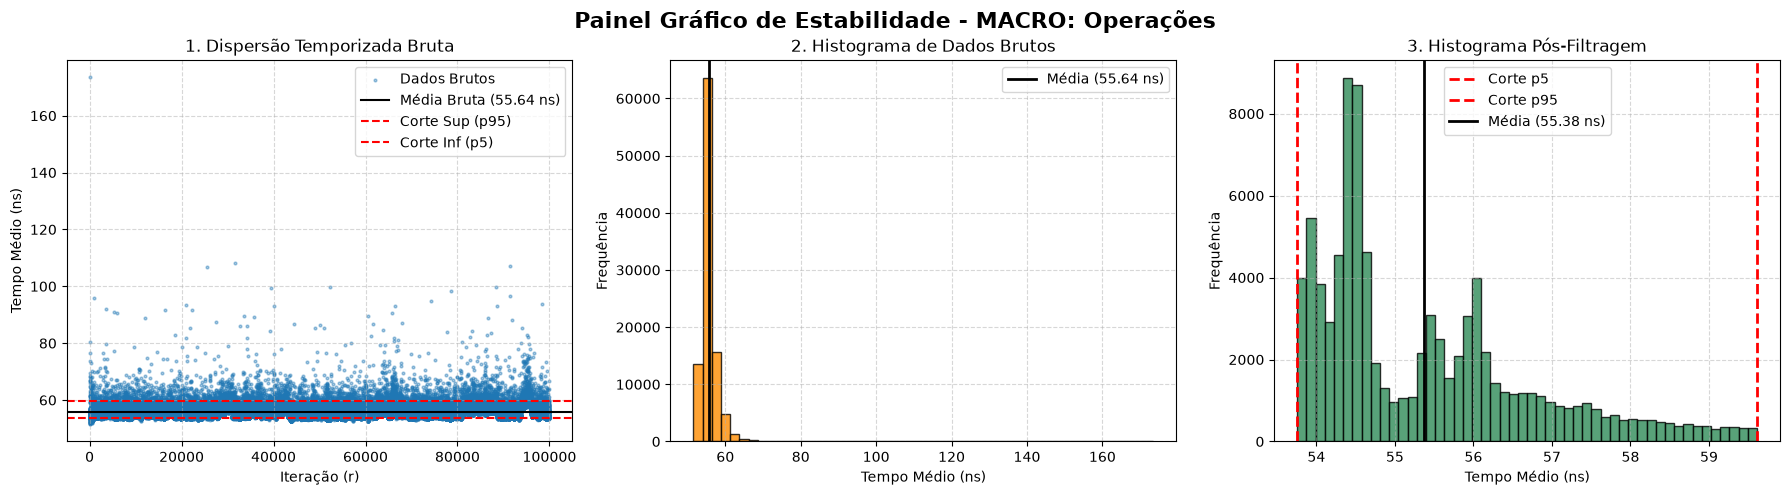

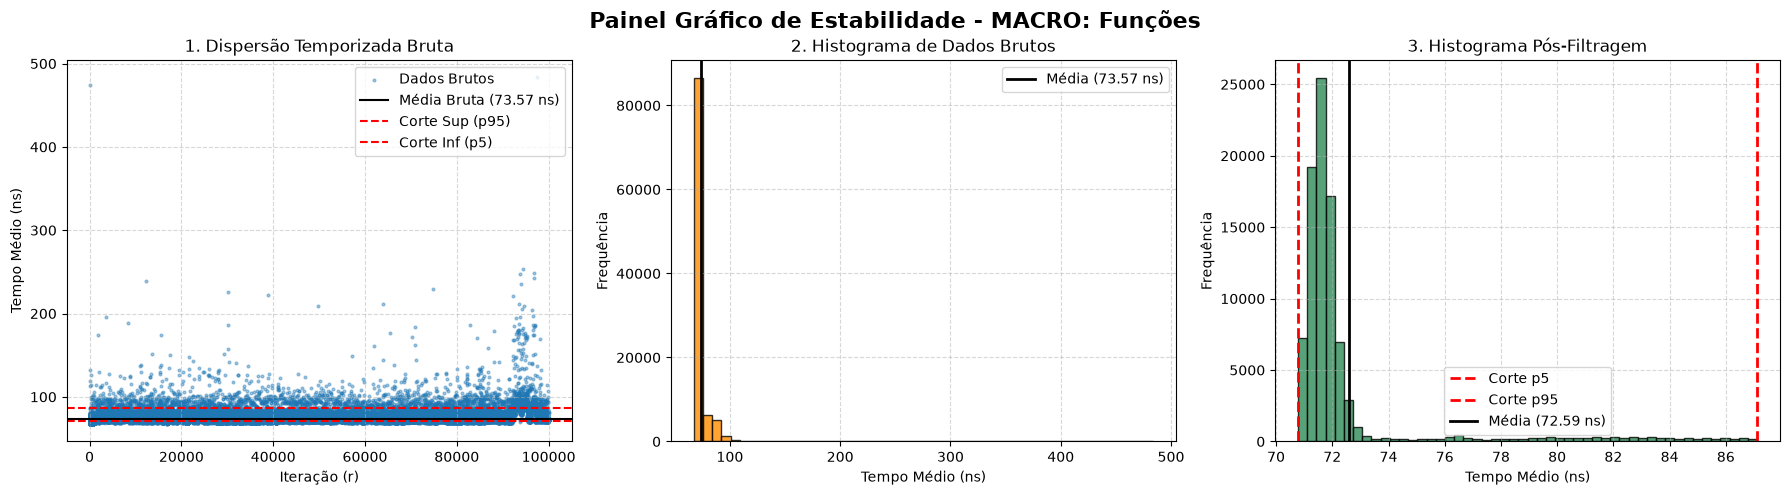

In [14]:
%matplotlib inline
import json
import os
import numpy as np
import matplotlib.pyplot as plt

CONFIG = {
    "arquivos": {
        "Atribuições": "../times_Atrib.json",
        "Comparações": "../times_Comp.json",
        "Operações": "../times_Oper.json",
        "Funções": "../times_Func.json"
    },
    "output_dir": "paineis_graficos_estabilidade",
    "n_amostra_interna": 100
}

os.makedirs(CONFIG["output_dir"], exist_ok=True)

# 1º NÍVEL DE INDENTAÇÃO: Laço das MACRO-primitivas
for nome_macro, arquivo in CONFIG["arquivos"].items():
    if not os.path.exists(arquivo):
        continue
    
    with open(arquivo, "r") as f:
        dados = json.load(f)
        
    listas_micro = []
    
    # 2º NÍVEL DE INDENTAÇÃO: Laço das MICRO-primitivas
    for op, tempos in dados.items():
        arr = (np.array(tempos, dtype=float) * 1e9) / CONFIG["n_amostra_interna"]
        listas_micro.append(arr)
        
    # =======================================================================
    # ATENÇÃO AQUI: Voltamos para o 1º NÍVEL DE INDENTAÇÃO!
    # O bloco abaixo roda apenas 1 VEZ para cada MACRO-primitiva.
    # =======================================================================
    
    # Agregando para a Macro-Primitiva (Calcula a média de todas as micros)
    arr_macro = np.mean(listas_micro, axis=0)
    iteracoes = np.arange(1, len(arr_macro) + 1)
    
    p5 = np.percentile(arr_macro, 5)
    p95 = np.percentile(arr_macro, 95)
    
    mascara_filtro = (arr_macro >= p5) & (arr_macro <= p95)
    arr_filtrado = arr_macro[mascara_filtro]
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Painel Gráfico de Estabilidade - MACRO: {nome_macro}", fontsize=16, fontweight='bold')
    
     # Calculando as médias
    media_bruta = np.mean(arr_macro)
    media_filtrada = np.mean(arr_filtrado)
    
    # --- SUBPLOT [0]: Dispersão ---
    axes[0].scatter(iteracoes, arr_macro, alpha=0.4, s=4, color="tab:blue", label="Dados Brutos")
    axes[0].axhline(media_bruta, color="black", linestyle="-", linewidth=1.5, label=f"Média Bruta ({media_bruta:.2f} ns)")
    axes[0].axhline(p95, color="red", linestyle="--", linewidth=1.5, label="Corte Sup (p95)")
    axes[0].axhline(p5, color="red", linestyle="--", linewidth=1.5, label="Corte Inf (p5)")
    axes[0].set_title("1. Dispersão Temporizada Bruta")
    axes[0].set_xlabel("Iteração (r)")
    axes[0].set_ylabel("Tempo Médio (ns)")
    axes[0].legend(loc="upper right")
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    # --- SUBPLOT [1]: Histograma Bruto ---
    axes[1].hist(arr_macro, bins=50, color='darkorange', alpha=0.8, edgecolor='black')
    
    # ADICIONANDO A LINHA DA MÉDIA BRUTA
    axes[1].axvline(media_bruta, color='black', linestyle='-', linewidth=2, label=f'Média ({media_bruta:.2f} ns)')
    
    axes[1].set_title("2. Histograma de Dados Brutos")
    axes[1].set_xlabel("Tempo Médio (ns)")
    axes[1].set_ylabel("Frequência")
    axes[1].legend() # Adiciona a legenda para mostrar a média
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    # --- SUBPLOT [2]: Histograma Filtrado ---
    axes[2].hist(arr_filtrado, bins=50, color='seagreen', alpha=0.8, edgecolor='black')
    axes[2].axvline(p5, color='red', linestyle='dashed', linewidth=2, label=f'Corte p5')
    axes[2].axvline(p95, color='red', linestyle='dashed', linewidth=2, label=f'Corte p95')
    
    # ADICIONANDO A LINHA DA MÉDIA FILTRADA
    axes[2].axvline(media_filtrada, color='black', linestyle='-', linewidth=2, label=f'Média ({media_filtrada:.2f} ns)')
    
    axes[2].set_title("3. Histograma Pós-Filtragem")
    axes[2].set_xlabel("Tempo Médio (ns)")
    axes[2].set_ylabel("Frequência")
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    
    # O plt.show() também deve estar no 1º nível de indentação
    plt.show()